# Symptom Analysis with Deep Learning

A reproducible PyTorch MLP project. This notebook imports the same data, model, training, and inference modules used by the application.

**Educational dataset only:** there are 304 unique patterns, undocumented patient-level provenance, and no clinical validation. A high score is not diagnostic accuracy.

In [1]:
from pathlib import Path
import sys
import tempfile

root = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "Training.csv").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from the HealthcareDL repository directory.")
sys.path.insert(0, str(root))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from healthdl.data import load_dataset, load_catalog, split_dataset
from healthdl.training import TrainConfig, train
from healthdl.inference import Predictor

## Audit and split

Merge duplicate symptom columns, normalize disease aliases, and deduplicate before partitioning. Every category appears in all three partitions. Pattern-level separation does not establish patient-level independence.

In [2]:
dataset = load_dataset()
partitions = split_dataset(dataset, seed=20)
display(pd.DataFrame([{
    "raw_rows": dataset.raw_rows, "unique_patterns": len(dataset.x),
    "features": len(dataset.features), "categories": len(dataset.class_ids),
    **{name: len(indices) for name, indices in partitions.items()}
}]))
print("Merged duplicate columns:", dataset.merged_columns)

,raw_rows,unique_patterns,features,categories,train,validation,test
0,4920,304,131,41,182,61,61


Merged duplicate columns: {'fluid_overload': [45, 117]}


## Train a neural network

Architecture: 131 → 128 → 64 → 41, ReLU, dropout 0.15, AdamW, and cross-entropy loss. Validation loss selects the checkpoint; test data is reserved for final reporting. Artifacts from this notebook go to a temporary directory, leaving the web app's bundle unchanged.

Selected epoch: 112 of 152


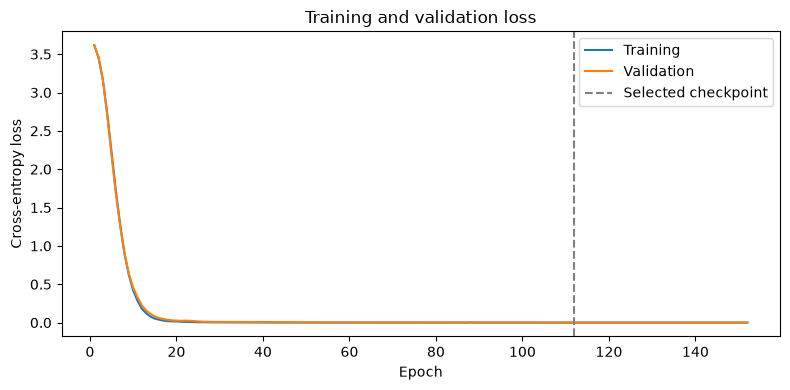

In [3]:
experiment = tempfile.TemporaryDirectory(prefix="healthcaredl-notebook-")
output_dir = Path(experiment.name)
report = train(TrainConfig(output_dir=output_dir, seed=20))
print("Selected epoch:", report["best_epoch"], "of", report["epochs_run"])
history = pd.DataFrame(report["history"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history.epoch, history.train_loss, label="Training")
ax.plot(history.epoch, history.validation_loss, label="Validation")
ax.axvline(report["best_epoch"], linestyle="--", color="gray", label="Selected checkpoint")
ax.set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Training and validation loss")
ax.legend()
fig.tight_layout()
plt.show()

## Held-out evaluation

Report macro F1 and per-category support alongside accuracy. The SVC is a comparison; the application serves the neural network. Do not tune architecture or thresholds repeatedly against this held-out test set.

In [4]:
display(pd.DataFrame({
    name: {key: report[name][key] for key in ["accuracy", "macro_f1"]}
    for name in ["validation", "test", "missing_one_symptom_test", "svc_baseline_test"]
}).T)
display(pd.DataFrame(report["test"]["per_class"]).T)
print("Serving policy:", report["serving_policy_test"])
print("Limitations:", *report["limitations"], sep="\n- ")

,accuracy,macro_f1
validation,1.0,1.0
test,1.0,1.0
missing_one_symptom_test,1.0,1.0
svc_baseline_test,1.0,1.0


,precision,recall,f1-score,support
acne,1.0,1.0,1.0,1.0
aids,1.0,1.0,1.0,1.0
alcoholic_hepatitis,1.0,1.0,1.0,2.0
allergy,1.0,1.0,1.0,1.0
arthritis,1.0,1.0,1.0,1.0
asthma,1.0,1.0,1.0,1.0
bppv,1.0,1.0,1.0,1.0
brain_hemorrhage,1.0,1.0,1.0,1.0
cervical_spondylosis,1.0,1.0,1.0,1.0
chickenpox,1.0,1.0,1.0,2.0


Serving policy: {'status_counts': {'match': 46, 'urgent': 15}, 'match_coverage': 0.7540983606557377, 'accuracy_among_matches': 1.0, 'note': 'Urgent messages and abstentions are not disease predictions; these heuristics are not clinically validated.'}
Limitations:
- Public file matches and publisher license declarations are recorded in data/SOURCES.md; original clinical collection and patient-level provenance remain unverified.
- Pattern-disjoint partitions are not independent clinical or patient-level validation.
- Related symptom templates may remain across partitions.
- Softmax scores are uncalibrated; no clinical accuracy or safety is established.
- Missing-symptom testing is synthetic, not a clinical evaluation.


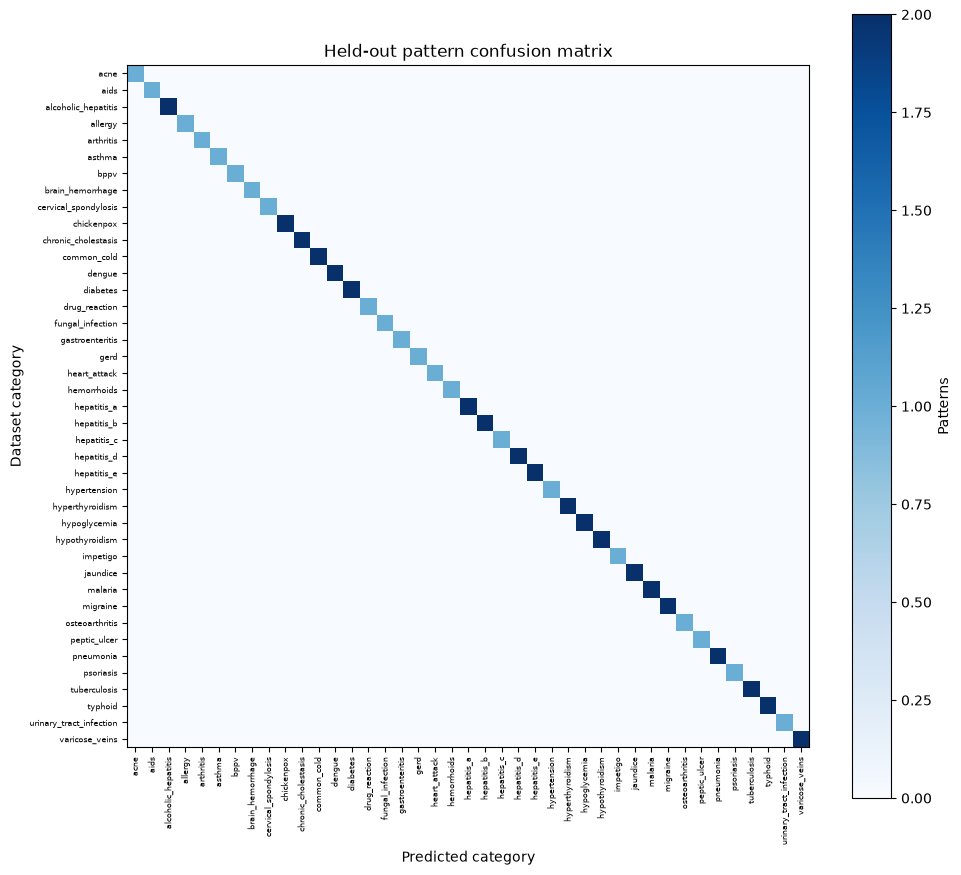

In [5]:
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(report["test"]["confusion_matrix"], cmap="Blues")
ax.set(xticks=range(len(dataset.class_ids)), yticks=range(len(dataset.class_ids)),
       xticklabels=dataset.class_ids, yticklabels=dataset.class_ids,
       xlabel="Predicted category", ylabel="Dataset category", title="Held-out pattern confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=6)
plt.setp(ax.get_yticklabels(), fontsize=6)
fig.colorbar(image, ax=ax, label="Patterns")
fig.tight_layout()
plt.show()

## Reload the exported network

Inference uses persisted feature order and stable category IDs. Sparse or unfamiliar input can abstain; designated symptoms show an urgent-care message. These are demonstration heuristics, not clinically validated rules. No prescriptions or personalized treatment advice are generated.

In [6]:
predictor = Predictor(output_dir)
for symptoms in [
    "itching, skin rash, nodal skin eruptions",
    "cough",
    "acidity, cold hands and feet, blackheads",
    "chest pain",
]:
    result = predictor.predict(symptoms)
    print(symptoms, "=>", result["status"], result.get("condition", {}).get("label", ""))
    print(result["message"])

itching, skin rash, nodal skin eruptions => match Fungal infection
A match to an example in the learning dataset. This is not a diagnosis.
cough => insufficient 
There is too little information for this demo to suggest a dataset match. Do not add symptoms you do not have. A healthcare professional can assess your concerns.
acidity, cold hands and feet, blackheads => unsupported 
This combination is outside the patterns this demo can support. A healthcare professional can help assess these symptoms.
chest pain => urgent 
These symptoms can require urgent medical assessment. If they are happening now, seek emergency care and do not wait for a result from this demo.


## Data and health information

Read `docs/DATASET.md` and `docs/MODEL_CARD.md` for evaluation limits and provenance gaps. Short condition descriptions link to MedlinePlus and have not undergone qualified clinical review for this project. The original recommendation tables and SVC pickle are quarantined under `data/legacy/` and are never loaded here. The app does not learn from user submissions.